In [114]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [115]:
from pathlib import Path

data_path = Path("./data")
companies =  pd.read_csv(data_path / "sp500_companies.csv")
index = pd.read_csv(data_path / "sp500_index.csv")
stocks = pd.read_csv(data_path / "sp500_stocks.csv")

In [116]:
print(f"Companies: {companies.shape}")
print(f"Index: {index.shape}")
print(f"Stocks: {stocks.shape}")

Companies: (502, 16)
Index: (2517, 2)
Stocks: (1891536, 8)


In [117]:
companies.head(3)

,Exchange,Symbol,Shortname,Longname,Sector,Industry,Currentprice,Marketcap,Ebitda,Revenuegrowth,City,State,Country,Fulltimeemployees,Longbusinesssummary,Weight
0,NMS,AAPL,Apple Inc.,Apple Inc.,Technology,Consumer Electronics,254.49,3846819807232,1.346610e+11,0.061,Cupertino,CA,United States,164000.0,"Apple Inc. designs, manufactures, and markets ...",0.069209
1,NMS,NVDA,NVIDIA Corporation,NVIDIA Corporation,Technology,Semiconductors,134.70,3298803056640,6.118400e+10,1.224,Santa Clara,CA,United States,29600.0,NVIDIA Corporation provides graphics and compu...,0.059350
2,NMS,MSFT,Microsoft Corporation,Microsoft Corporation,Technology,Software - Infrastructure,436.60,3246068596736,1.365520e+11,0.160,Redmond,WA,United States,228000.0,Microsoft Corporation develops and supports so...,0.058401


- Exchange (sàn giao dịch): sàn cổ phiếu niêm yết vào giao dịch
- Symbol: Mã chứng khoán
- Sector: Lĩnh vực kinh doanh (rộng)
- Indudstry: ngành nghề chi tiết
- Currentprice: Giá cổ phiếu hiện tại
- Marketcap: Vốn hóa thị trường
- Ebitda: Lợi nhuận trước lãi vay, thuế, và khấu hao
- Revenuegrowth: Tăng trường doanh thu so với kỳ trước
- Weight: Tỉ trọng chỉ số

In [118]:
index.head(3)

,Date,S&P500
0,2014-12-22,2078.54
1,2014-12-23,2082.17
2,2014-12-24,2081.88


In [119]:
stocks.head(3)

,Date,Symbol,Adj Close,Close,High,Low,Open,Volume
0,2010-01-04,MMM,NaN,NaN,NaN,NaN,NaN,NaN
1,2010-01-05,MMM,NaN,NaN,NaN,NaN,NaN,NaN
2,2010-01-06,MMM,NaN,NaN,NaN,NaN,NaN,NaN


- Open: Giá mở cửa
- High: Giá cao nhất trong phiên giao dịch
- Low: Giá thấp nhất trong phiên giao dịch
- Close: Giá đóng cửa
- Adj Close: Giá đóng cửa hiệu chỉnh (cột qun trong nhất, phản ánh các hành động của công ty)
- Volume: Tổng khối lượng giao dịch

In [120]:
# Gộp 3 file lại
# companies - stocks: Thông qua Symbol
# index - stocks: thông qua date
inclusive_symbol = ['GOOG', 'NVDA', 'MSFT', 'AMZN']

stock_merge = pd.merge(stocks, companies, on='Symbol', how='inner')

sp500_panel_data = pd.merge(stock_merge, index, on='Date', how='inner')
sp500_panel_data['Date'] = pd.to_datetime(sp500_panel_data['Date'])
sp500_panel_data = sp500_panel_data[
    sp500_panel_data['Symbol'].isin(inclusive_symbol)
]

df_master = sp500_panel_data

In [121]:
df_master.info()

<class 'pandas.DataFrame'>
Index: 10068 entries, 50340 to 875915
Data columns (total 24 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Date                 10068 non-null  datetime64[us]
 1   Symbol               10068 non-null  str           
 2   Adj Close            10068 non-null  float64       
 3   Close                10068 non-null  float64       
 4   High                 10068 non-null  float64       
 5   Low                  10068 non-null  float64       
 6   Open                 10068 non-null  float64       
 7   Volume               10068 non-null  float64       
 8   Exchange             10068 non-null  str           
 9   Shortname            10068 non-null  str           
 10  Longname             10068 non-null  str           
 11  Sector               10068 non-null  str           
 12  Industry             10068 non-null  str           
 13  Currentprice         10068 non-null  float

In [122]:
df_master.head(3)

,Date,Symbol,Adj Close,Close,High,Low,Open,Volume,Exchange,Shortname,...,Marketcap,Ebitda,Revenuegrowth,City,State,Country,Fulltimeemployees,Longbusinesssummary,Weight,S&P500
50340,2014-12-22,GOOG,26.077946,26.171646,26.250929,25.733349,25.733349,54475152.0,NMS,Alphabet Inc.,...,2351623045120,1.234700e+11,0.151,Mountain View,CA,United States,181269.0,Alphabet Inc. offers various products and plat...,0.042309,2078.54
50341,2014-12-23,GOOG,26.362141,26.456863,26.654819,26.242451,26.277855,43952341.0,NMS,Alphabet Inc.,...,2351623045120,1.234700e+11,0.151,Mountain View,CA,United States,181269.0,Alphabet Inc. offers various products and plat...,0.042309,2082.17
50342,2014-12-24,GOOG,26.271715,26.366112,26.515154,26.278851,26.452873,14118657.0,NMS,Alphabet Inc.,...,2351623045120,1.234700e+11,0.151,Mountain View,CA,United States,181269.0,Alphabet Inc. offers various products and plat...,0.042309,2081.88


In [123]:
# Vẽ time plot
# Adj Close
# Volume
# S&P500

def time_plot(df, symbols: list):


    fig, axes = plt.subplots(nrows = 3, ncols=2, figsize=(14, 10))
    fig.suptitle("Time Plot", fontsize=16)

    for symbol in symbols:
        df_symbol = df[df['Symbol'] == symbol]

        dates = df_symbol['Date']
        axes[0, 0].plot(dates, df_symbol['Adj Close'], label=symbol)
        axes[0, 0].set_title("Adj Close")

        axes[0, 1].plot(dates, df_symbol['Volume'], label=symbol)
        axes[0, 1].set_title("Volume")

        axes[1, 0].plot(dates, df_symbol['Open'], label=symbol)
        axes[1, 0].set_title("Open")

        axes[1, 1].plot(dates, df_symbol['Close'], label=symbol)
        axes[1, 1].set_title("Close")

        axes[2, 0].plot(dates, df_symbol['High'], label=symbol)
        axes[2, 0].set_title("High")

        axes[2, 1].plot(dates, df_symbol['Low'], label=symbol)
        axes[2, 1].set_title("Low")



    for ax in axes.flat:
        ax.legend()

    plt.tight_layout(pad=3.0, h_pad=2.5, w_pad=2.0)
    plt.show()



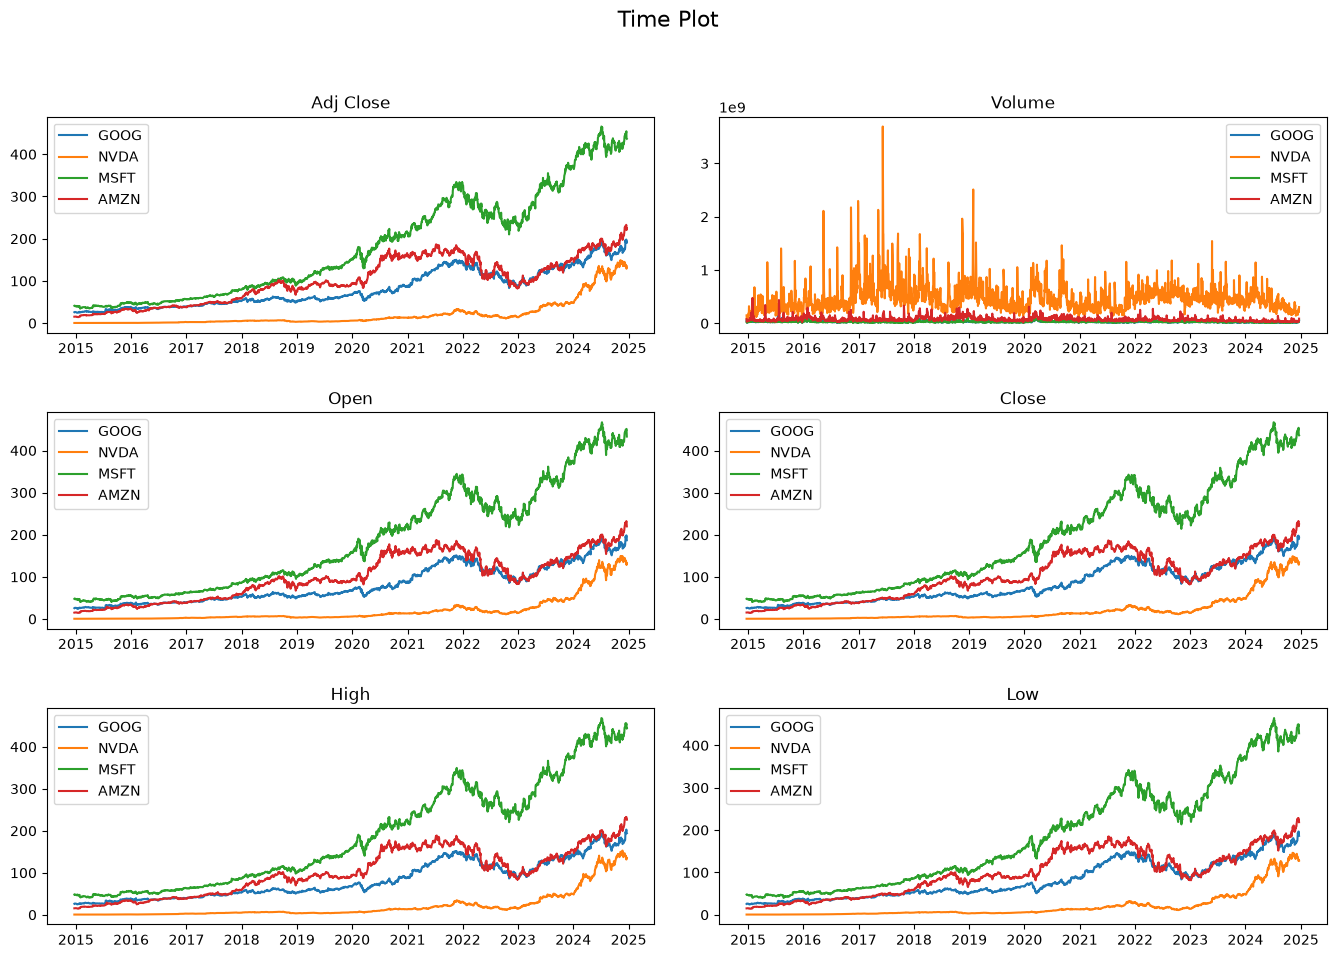

In [124]:
time_plot(df_master, inclusive_symbol)

Observation about Trend:
- All four stocks experience a strong, long-term upward trend.
- MSFT holds the highest absolute price among the four.
- Although NVDA has the lowest absolute price, it shows the strongest growth in recent years (2023-2025).

Observation about Seasonality:
- There is no clear sign of seasonal patterns in the long term.
- Price fluctuations are based on market conditions rather than strict seasonal cycles.

Observation About Noise:
- Noise is clearly visible through the daily fluctuations and the jagged price lines.
- The Volume plot is highly dominated by noise, showing random, unpredictable spikes (especially for NVDA) without a clear trend.

In [128]:
lag_dict = {}

for symbol in inclusive_symbol:
    n = df_master[df_master['Symbol'] == symbol]['Close'].count()

    max_lag = int(min(10 * np.log10(n), n / 5)) if n > 0 else 0

    lag_dict[symbol] = max_lag

print(lag_dict)

{'GOOG': 34, 'NVDA': 34, 'MSFT': 34, 'AMZN': 34}
